In [347]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
from typing import List, Any, Dict
from dataclasses import dataclass

## 📊 Data Preparation

In [348]:
df = pd.read_csv("./Student lifestyle data.csv")

### 📊 Data Preparation - Structural Analysis

#### 📊 Informasi Umum Dataset

In [349]:
print('5 sample dataset')
df.sample(5)

5 sample dataset


,Student_ID,Age,Gender,Department,CGPA,Sleep_Duration,Study_Hours,Social_Media_Hours,Physical_Activity,Stress_Level
66958,67959,22.0,Male,Engineering,2.56,6.2,6.6,2.8,132.0,4.0
89128,90129,21.0,Female,Science,3.32,NaN,3.0,2.4,135.0,4.0
14868,15869,22.0,Male,Business,3.13,NaN,3.5,0.2,NaN,6.0
61438,62439,NaN,Male,Medical,2.58,7.5,3.1,4.8,68.0,5.0
54985,55986,22.0,Male,Arts,3.59,6.9,8.1,4.2,119.0,5.0


In [350]:
print(f'Dataset memiliki {df.shape[0]} rows dan {df.shape[1]} columns')

Dataset memiliki 100000 rows dan 10 columns


In [351]:
df.shape

(100000, 10)

In [352]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 10 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Student_ID          100000 non-null  int64  
 1   Age                 98000 non-null   float64
 2   Gender              98000 non-null   object 
 3   Department          98000 non-null   object 
 4   CGPA                98000 non-null   float64
 5   Sleep_Duration      98000 non-null   float64
 6   Study_Hours         98000 non-null   float64
 7   Social_Media_Hours  98000 non-null   float64
 8   Physical_Activity   98000 non-null   float64
 9   Stress_Level        98000 non-null   float64
dtypes: float64(7), int64(1), object(2)
memory usage: 7.6+ MB


✍️ Terdapat **indikasi missing value** </br>
✍️ Tipe data pada dataset ini ada **8 numerik dan 2 object** </br>
✍️ Semua tipe data pada masing-masing kolom sudah sesuai, **tidak perlu casting** </br>

#### 📊 Separasi feature dan target

In [353]:
X = df.drop(columns=['Student_ID', 'Stress_Level'])
y = df['Stress_Level']

#### 📊 Cek Distribusi Target

<Axes: xlabel='Stress_Level'>

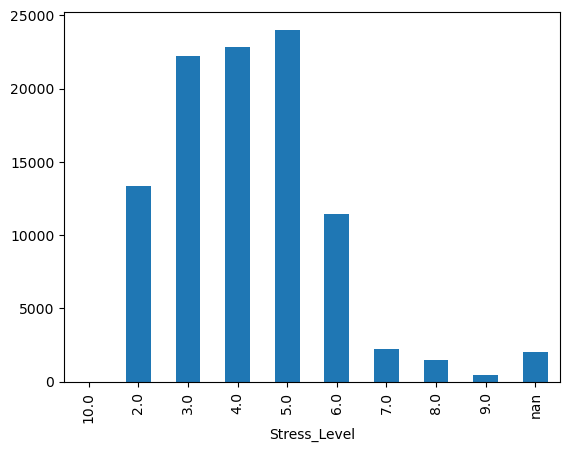

In [354]:
y.astype(str).value_counts().sort_index().plot(kind='bar')

✍️ Target **imbalanced** </br>
✍️ Didominasi oleh class 3.0 - 5.0, disusul class 2.0 dan 6.0, dan **paling sedikit adalah class 7.0 - 10.0** </br>
✍️ Terdapat **missing value** pada target </br>

#### 📊 Separasi feature numerik dan kategorik

In [355]:
num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(include='object').columns.tolist()

print(cat_cols)

['Gender', 'Department']


#### 📊 Statistik Deskriptif Feature

In [356]:
num_desc = X[num_cols].describe().T
num_to_cat_desc = X[num_cols].dropna().astype(str).describe().T.drop(columns=['count'])
num_overall_desc = pd.concat([num_desc, num_to_cat_desc], axis=1)

cat_desc = X[cat_cols].dropna().describe().T

In [357]:
print('Statistik deskriptif kolom numerik')
display(num_overall_desc)

print('Statistik deskriptif kolom numerik')
display(num_desc)

print('Statistik deskriptif kolom kategorik')
display(cat_desc)

Statistik deskriptif kolom numerik


,count,mean,std,min,25%,50%,75%,max,unique,top,freq
Age,98000.0,21.009020,2.000311,18.00,19.00,21.0,23.00,24.0,7,22.0,12832
CGPA,98000.0,2.897737,0.532342,1.56,2.45,2.9,3.35,4.0,237,3.25,542
Sleep_Duration,98000.0,6.994409,1.498520,3.00,6.00,7.0,8.00,12.0,91,7.0,2422
Study_Hours,98000.0,4.510430,1.976138,0.00,3.20,4.5,5.80,12.8,124,4.6,1795
Social_Media_Hours,98000.0,3.503534,1.486421,0.00,2.50,3.5,4.50,10.0,97,3.3,2371
Physical_Activity,98000.0,74.354439,43.363699,0.00,37.00,74.0,112.00,149.0,150,53.0,663


Statistik deskriptif kolom numerik


,count,mean,std,min,25%,50%,75%,max
Age,98000.0,21.009020,2.000311,18.00,19.00,21.0,23.00,24.0
CGPA,98000.0,2.897737,0.532342,1.56,2.45,2.9,3.35,4.0
Sleep_Duration,98000.0,6.994409,1.498520,3.00,6.00,7.0,8.00,12.0
Study_Hours,98000.0,4.510430,1.976138,0.00,3.20,4.5,5.80,12.8
Social_Media_Hours,98000.0,3.503534,1.486421,0.00,2.50,3.5,4.50,10.0
Physical_Activity,98000.0,74.354439,43.363699,0.00,37.00,74.0,112.00,149.0


Statistik deskriptif kolom kategorik


,count,unique,top,freq
Gender,96045,2,Male,48103
Department,96045,5,Science,19281


✍️ Mean dan median pada feature numerik relatif seimbang, **indikasi tidak ada nilai ekstrem** </br>
✍️ Semua feature numerik **memiliki variansi**, tidak ada yang informasinya konstan </br>
✍️ **Tidak ada nilai negatif** namun terdapat **nilai nol** pada feature numerik </br>
✍️ Berdasarkan nilai **Min dan Max** pada feature numerik, skala antar feature cukup berbeda dan perlu **di normalisasi** </br>
✍️ **Low Cardinality** pada kolom kategorik, `Gender` aman di **Binary Encoding** dan `Department` aman di **One-Hot Encoding** </br>

In [358]:
# untuk imputasi jika diperlukan
num_median = num_overall_desc['50%']
cat_mode = cat_desc['top']

#### 📊 Cek Unique Value pada Feature Kategorik

In [359]:
for col in cat_cols:
    print(f'Unique value pada kolom {col}\n{X[col].astype(str).unique()}\n')

Unique value pada kolom Gender
['Female' 'Male' 'nan']

Unique value pada kolom Department
['Science' 'Engineering' 'Medical' 'Arts' 'Business' 'nan']



✍️ Tidak ada nilai anomali pada feature kategorik

#### 📊 Cek Duplikasi

In [360]:
print(f'Rasio baris duplikat: {df.duplicated().mean()}')

Rasio baris duplikat: 0.0


In [361]:
print(f'Rasio duplikat pada Student_ID: {df.duplicated(subset="Student_ID").mean()}')

Rasio duplikat pada Student_ID: 0.0


✍️ **Tidak ada row dan ID yang duplikat**

#### 📊 Analisa Missing Value

Text(0.5, 1.0, 'Missing spreadness')

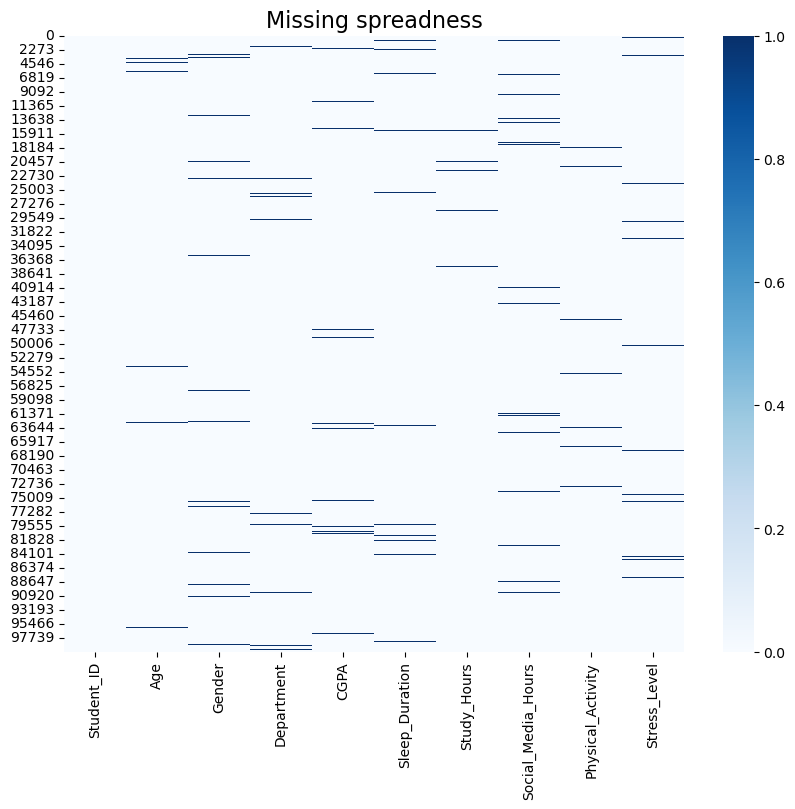

In [362]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.isna(), cmap='Blues')
plt.title('Missing spreadness', fontsize=16)

✍️ Row row tertentu nampak **Missing value berbarengan**

In [363]:
df.isna().sum()

Student_ID               0
Age                   2000
Gender                2000
Department            2000
CGPA                  2000
Sleep_Duration        2000
Study_Hours           2000
Social_Media_Hours    2000
Physical_Activity     2000
Stress_Level          2000
dtype: int64

In [364]:
print(f'Rasio row yang memiliki missing value: {df.isna().any(axis=1).mean()}')

Rasio row yang memiliki missing value: 0.16631


✍️ Drop missing value akan **kehilangan ~16.6%** row data

In [365]:
miss_ratio = X.isna().mean()
miss_cols = miss_ratio[miss_ratio.gt(0.0)].index.tolist()

results = []

for col in miss_cols:
    miss_flag = X[col].isna().astype(int)
    ct = pd.crosstab(miss_flag, y, normalize='columns')
    miss_rate = ct.loc[1] if 1 in ct.index else (ct.iloc[0] * 0.0)
    miss_gap_across_target = miss_rate.max() - miss_rate.min()

    results.append({
        'cols': col,
        'dtype': X[col].dtype,
        'miss_ratio': miss_ratio[col],
        'miss_gap_across_target': miss_gap_across_target
    })

pd.DataFrame(results, columns=['cols', 'dtype', 'miss_ratio', 'miss_gap_across_target']).sort_values(by='miss_gap_across_target', ascending=False)

,cols,dtype,miss_ratio,miss_gap_across_target
7,Physical_Activity,float64,0.02,0.237207
3,CGPA,float64,0.02,0.025586
1,Gender,object,0.02,0.023745
5,Study_Hours,float64,0.02,0.022051
6,Social_Media_Hours,float64,0.02,0.021614
4,Sleep_Duration,float64,0.02,0.021436
0,Age,float64,0.02,0.020964
2,Department,object,0.02,0.020964


✍️ `Physical Activity` memiliki **missingness pattern yang tinggi**, akan di handle dengan **missing indicator** </br>
✍️ Missing value pada kolom **numerik** akan di imputasi dengan **grouped-median** sementara kolom **kategorik** dengan **modus** </br>

In [366]:
# imputasi kolom kategorik
for col in cat_cols:
    mode = cat_mode[col]
    X[col] = X[col].fillna(mode)
    print(f'Rasio missing value pada {col} setelah handle: {X[col].isna().mean()}')

Rasio missing value pada Gender setelah handle: 0.0
Rasio missing value pada Department setelah handle: 0.0


In [367]:
# missing indicator pada Physical_Activity
X['is_missing_Physical_Activitty'] = X['Physical_Activity'].isna().astype(int)

In [368]:
num_cols.append('is_missing_Physical_Activitty')

In [369]:
# imputasi kolom numerik
for col in num_cols:
    median_group = X.groupby('Department')[col].transform('median')
    X[col] = X[col].fillna(median_group)
    print(f'Rasio missing value pada {col} setelah handle: {X[col].isna().mean()}')

Rasio missing value pada Age setelah handle: 0.0
Rasio missing value pada CGPA setelah handle: 0.0
Rasio missing value pada Sleep_Duration setelah handle: 0.0
Rasio missing value pada Study_Hours setelah handle: 0.0
Rasio missing value pada Social_Media_Hours setelah handle: 0.0
Rasio missing value pada Physical_Activity setelah handle: 0.0
Rasio missing value pada is_missing_Physical_Activitty setelah handle: 0.0


In [370]:
# imputasi target
y = y.fillna(y.mode().values[0])
y.astype(str).value_counts(normalize=True)

Stress_Level
5.0     0.26025
4.0     0.22838
3.0     0.22229
2.0     0.13321
6.0     0.11428
7.0     0.02212
8.0     0.01474
9.0     0.00469
10.0    0.00004
Name: proportion, dtype: float64

### 📊 Data Preparation - Feature Distribution Analysis

#### 📊 Distribusi Feature Numerik

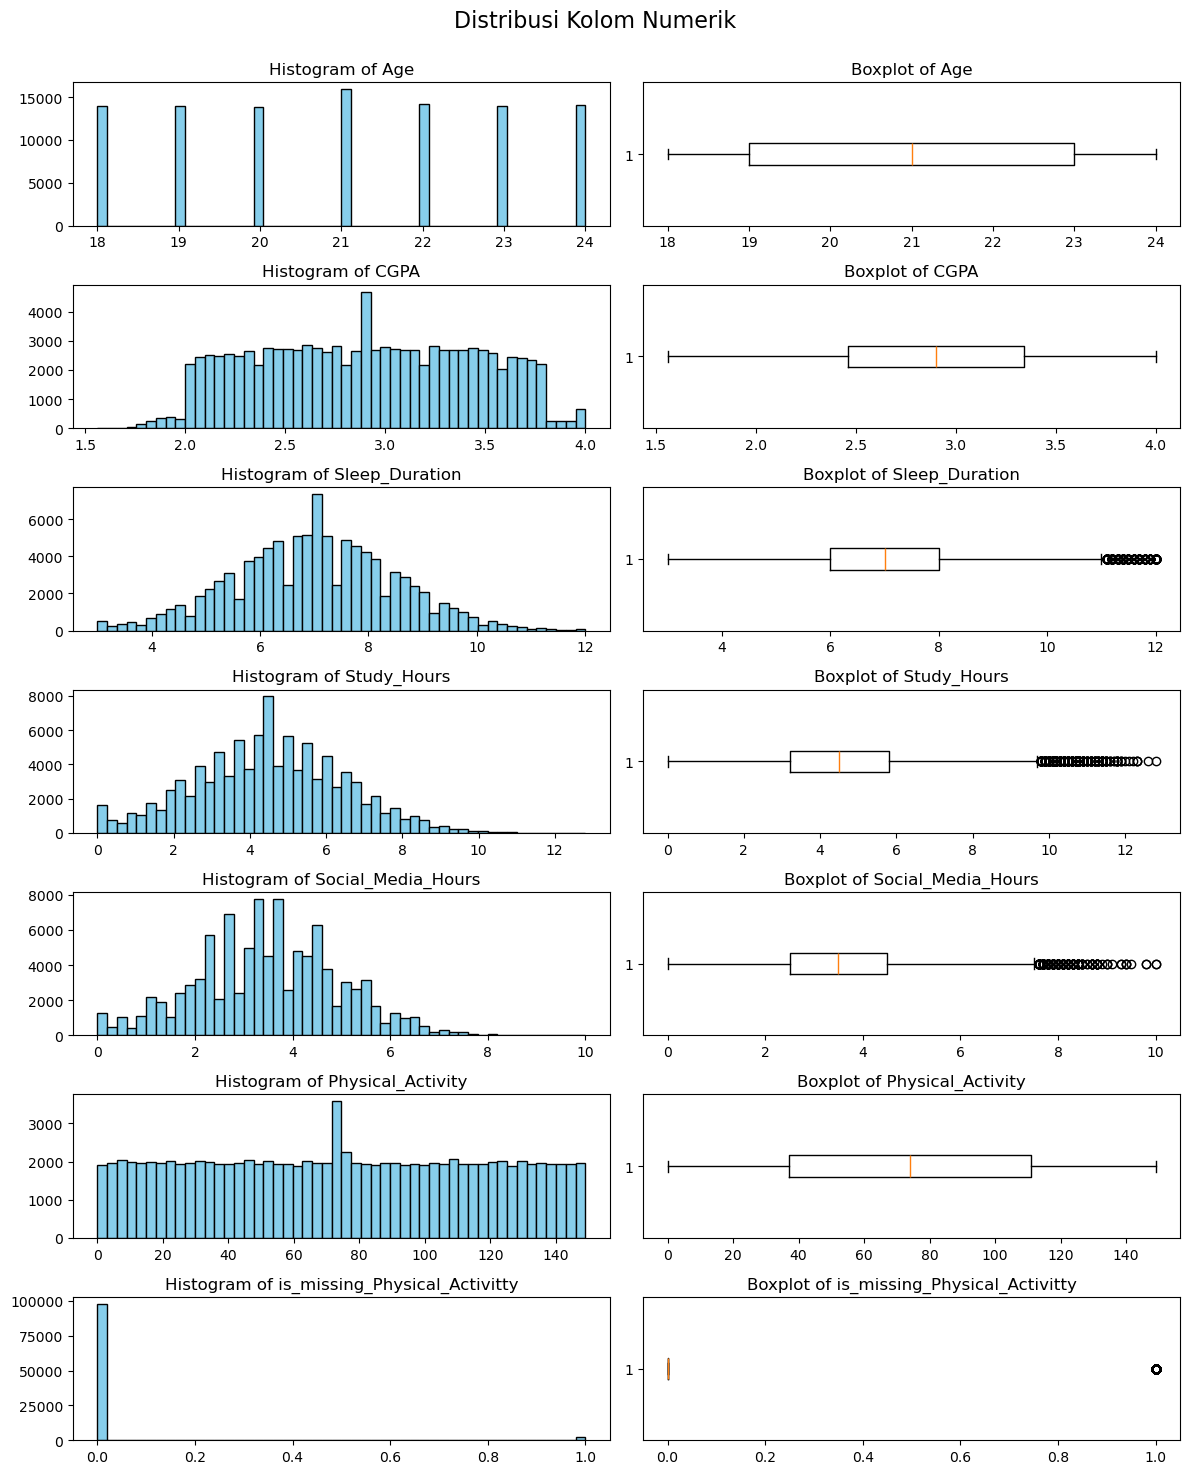

In [371]:
fig, axes = plt.subplots(nrows=len(num_cols), ncols=2, figsize=(12, 15))

for i in range(len(num_cols)):
    col = num_cols[i]
    
    axes[i, 0].hist(X[col], bins=50, color='skyblue', edgecolor='black')
    axes[i, 0].set_title(f'Histogram of {col}', fontsize=12)
    
    axes[i, 1].boxplot(X[col], vert=False)
    axes[i, 1].set_title(f'Boxplot of {col}', fontsize=12)

plt.suptitle('Distribusi Kolom Numerik', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.98])

#### 📊 Identifikasi outlier kolom numerik

In [372]:
# Identifikasi Outlier dengan Metode IQR
def outlier_iqr(col: pd.Series):
    Q1 = col.quantile(0.25)
    Q3 = col.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = col[(col < lower_bound) | (col > upper_bound)].index.to_list()

    return outliers


# Identifikasi Outlier dengan Metode Z-Score
def outlier_zscore(col: pd.Series, thresh: float = 3.0):
    mean = col.mean()
    std = col.std()
    
    zscore = (col - mean) / std

    outliers = zscore[(zscore < -thresh) | (zscore > thresh)].index.to_list()

    return outliers


# Identifikasi Outlier dengan Metode MAD
def outlier_mad(col:pd.Series, thresh: float=3.0):
    median = col.median()

    mad = np.median(np.abs(col - median))

    modified_z = 0.6745 * (col -median) / mad

    outliers = modified_z[(modified_z < -thresh) | (modified_z > thresh)].index.to_list()

    return outliers


# Wrap Outlier
def outliers_wrapper(col: pd.Series):

    iqr = set(outlier_iqr(col))
    zscore = set(outlier_zscore(col))
    mad = set(outlier_mad(col))

    all_idx = iqr | zscore | mad
    results  = {
        'weak' : 0,
        'strong': 0,
        'extreme' : 0
    }

    for idx in all_idx:
        vote = (idx in iqr) + (idx in zscore) + (idx in mad)

        if vote == 1:
            results['weak'] += 1
        elif vote ==2:
            results['strong'] += 1
        elif vote == 3:
            results['extreme'] += 1

    return results

In [373]:
for col in num_cols:
    print(f'Outlier in {col}:\n{outliers_wrapper(X[col])}\n')

Outlier in Age:
{'weak': 0, 'strong': 0, 'extreme': 0}

Outlier in CGPA:
{'weak': 0, 'strong': 0, 'extreme': 0}

Outlier in Sleep_Duration:
{'weak': 189, 'strong': 0, 'extreme': 168}

Outlier in Study_Hours:
{'weak': 227, 'strong': 28, 'extreme': 170}

Outlier in Social_Media_Hours:
{'weak': 175, 'strong': 0, 'extreme': 140}

Outlier in Physical_Activity:
{'weak': 0, 'strong': 0, 'extreme': 0}

Outlier in is_missing_Physical_Activitty:
{'weak': 0, 'strong': 0, 'extreme': 2000}



#### 📊 Summary kolom numerik

✍️ **Bentuk Tipe Data** </br>
- `Age` = Diskrit ordinal
- `CGPA`, `Sleep_Duration`, `Study_Hours`, `Social_Media_Hours`, `Physical_Activity` = Kontinu
- `is_missing_Physical_Activity` = Binary </br>

✍️ **Bentuk Distribusi Data** </br>
- `Age` = Diskrit Uniform-ish
- `CGPA` = Unimodal Normal-ish, range kecil
- `Sleep_Duration` = Unimodal Normal-ish
- `Study_Hours` dan `Social_Media_Hours` = Right-skewed ringan
- `Physical_Activity` = Uniform-ish, range relatif besar
- `is_missing_Physical_Activity` = Imbalanced </br>

✍️ **Outlier** </br>
- `Sleep_Duration`, `Study_Hours`, `Social_Media_Hours` = Memiliki Outlier eksrem
- `is_missing_Physical_Activity` = Bukan outlier, tapi **rare event feature** </br></br>

**⚙️ Implikasi Model**
- Feature numerik sudah kompatibel untuk diproses oleh LR
- Fit model LR beresiko "ketarik" oleh feature yang **skew** dan memiliki **nilai ekstrem** 
- **Skala** yang berbeda antar feature membuat proses training menjadi **tidak fair**
  
**🎯 Action**
- Pastikan *missing indicator* tetap ikut ke `num_cols`, dan lakukan encoding feature kategorik
- Feature numerik yang skew dan memiliki nilai ekstrem akan di **capping** ke P1 atau P99
- Semua feature numerik akan **di standardisasi (scaling)**

#### 📊 Eksekusi: Outlier Clipping

In [374]:
outlier_cols = num_cols[2:5]

for col in outlier_cols:
    p1, p99 = X[col].quantile(0.01), X[col].quantile(0.99)
    X[col] = X[col].clip(p1, p99)
    
    print(f'Outlier in {col} after clipping:\n{outliers_wrapper(X[col])}\n')

Outlier in Sleep_Duration after clipping:
{'weak': 0, 'strong': 0, 'extreme': 0}

Outlier in Study_Hours after clipping:
{'weak': 0, 'strong': 0, 'extreme': 0}

Outlier in Social_Media_Hours after clipping:
{'weak': 0, 'strong': 0, 'extreme': 0}



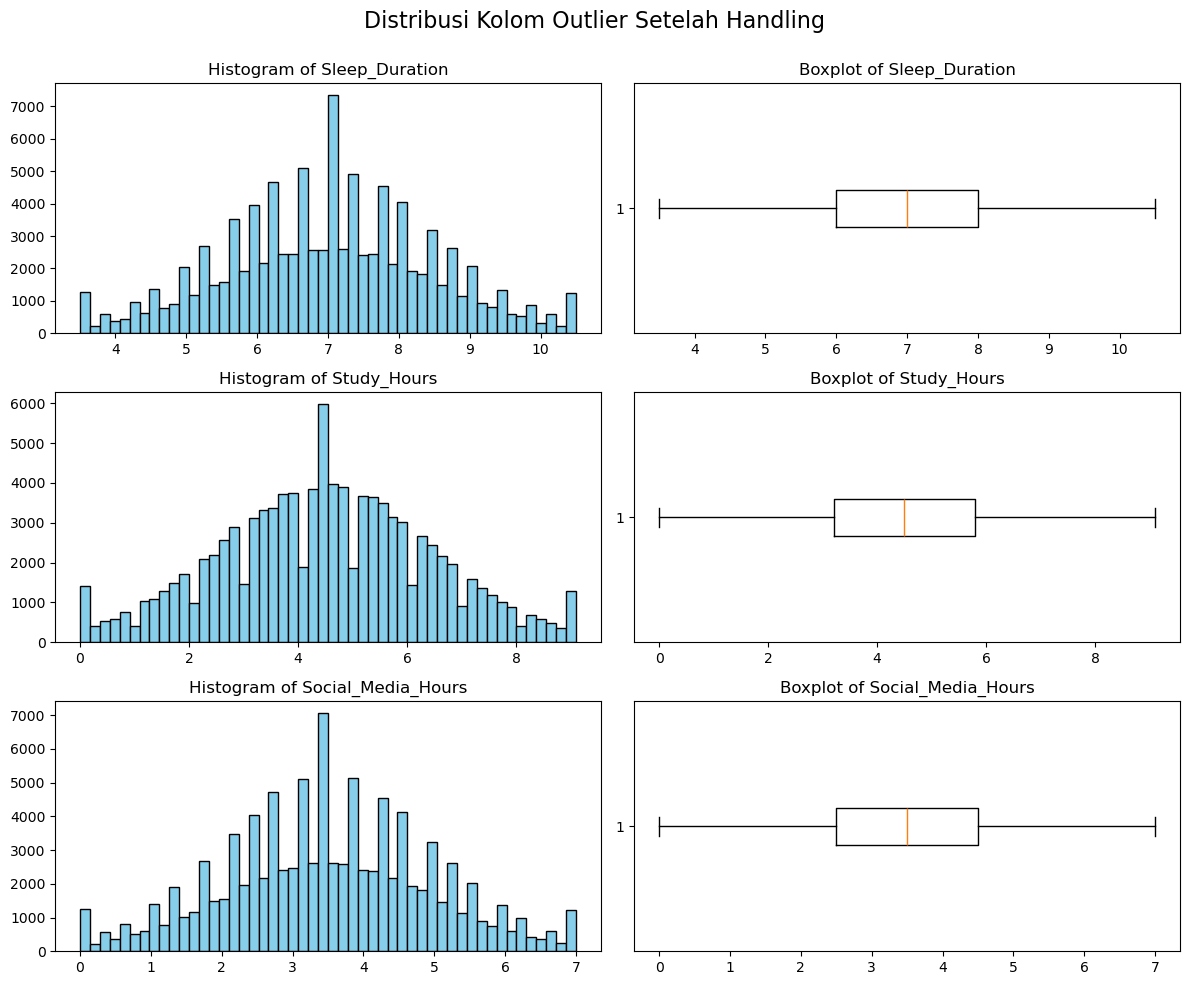

In [375]:
fig, axes = plt.subplots(nrows=len(outlier_cols), ncols=2, figsize=(12, 10))

for i in range(len(outlier_cols)):
    col = outlier_cols[i]
    
    axes[i, 0].hist(X[col], bins=50, color='skyblue', edgecolor='black')
    axes[i, 0].set_title(f'Histogram of {col}', fontsize=12)
    
    axes[i, 1].boxplot(X[col], vert=False)
    axes[i, 1].set_title(f'Boxplot of {col}', fontsize=12)

plt.suptitle('Distribusi Kolom Outlier Setelah Handling', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.98])

#### 📊 Eksekusi: Standard Scaling Preparation

In [376]:
class StandardScaler:

    def __init__(self):
        self.mean = None
        self.std = None
        self.columns = None

    def fit(self, X):
        self.columns = X.columns

        X_np = X.values.astype(float)

        self.mean = X_np.mean(axis=0)
        self.std = X_np.std(axis=0)
        self.std = np.where(self.std == 0, 1e-8, self.std)

        return self

    def transform(self, X):
        X_np = X.values.astype(float)

        X_scaled = (X_np - self.mean) / self.std

        return pd.DataFrame(X_scaled, columns=self.columns, index=X.index)

    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)

📝 Hanya menyiapkan, scaling akan di eksekusi di modul selanjutnya **Data Classification**

#### 📊 Distribusi Kolom Kategorik

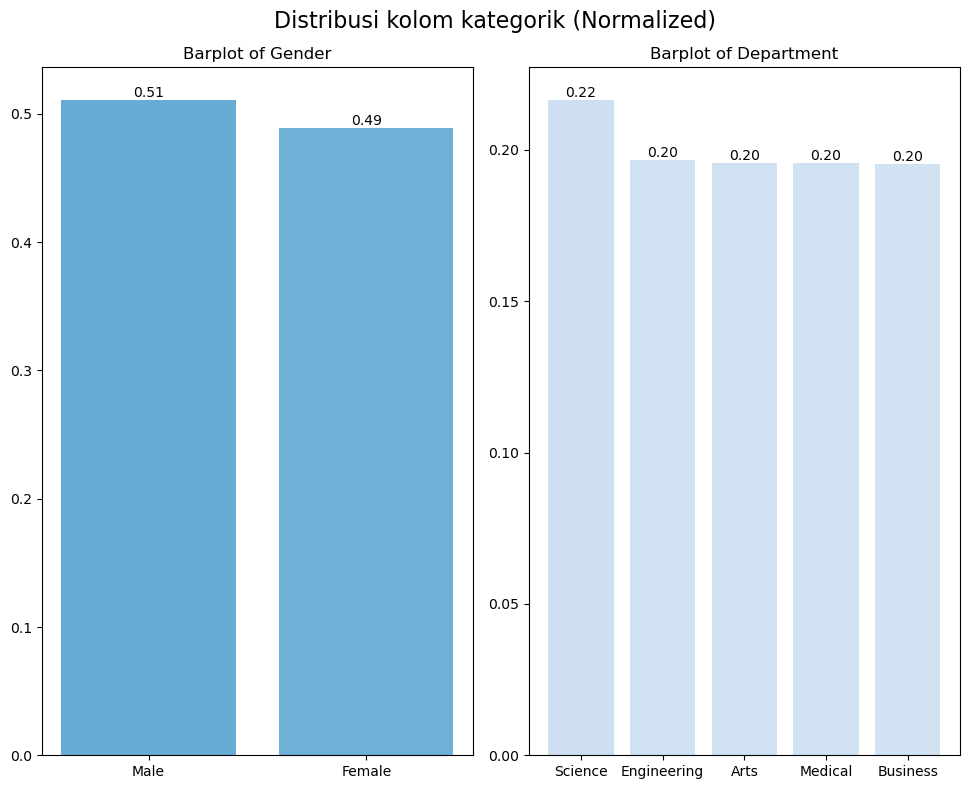

In [377]:
plt.figure(figsize=(10, 8))

for i in range(len(cat_cols)):
    col = cat_cols[i]
    vc = X[col].value_counts(normalize=True)
    colors = plt.cm.Blues(vc.values)

    plt.subplot(int(len(cat_cols)/2), 2, i+1)
    bars = plt.bar(vc.index, vc.values, color=colors)
    plt.bar_label(bars, fmt="%.2f")
    plt.title(f'Barplot of {col}', fontsize=12)

plt.suptitle('Distribusi kolom kategorik (Normalized)', fontsize=16)
plt.tight_layout(rect=[0, 0, 0.98,1])


✍️ **Distribusi kolom kategorik** 

`Gender`
- Insight -> Distribusi **hampir seimbang** (Male ~51%, Female ~49%)
- Implikasi model -> Resiko bias kecil, koefisien kolom `Gender` akan relatif stabil
- Action -> **Binary map**, dengan kategori `Male` sebagai reference, ubah nama kolom menjadi `is_male`

`Department`
- Insight -> Distribusi cukup merata 
- Implikasi model -> Resiko bias kecil, ketika di **OHE** akan minim sparse dan nilainya merata. 
- Action -> **One hot encoding** dengan `Science` sebagai baseline

### 📊 Relationship Analysis

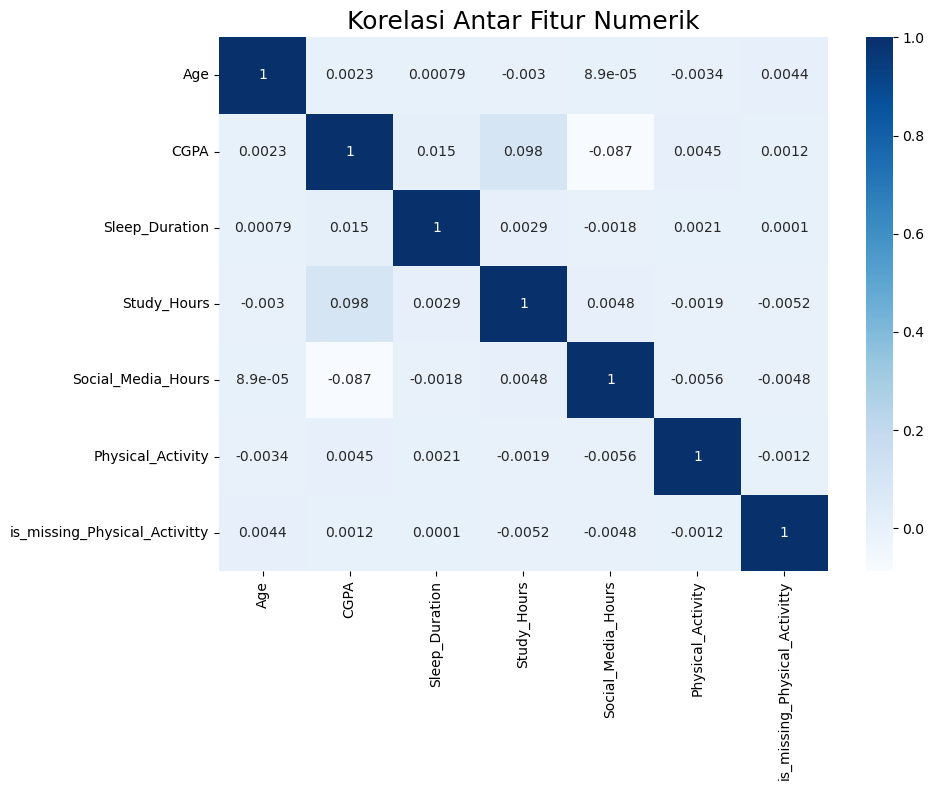

In [378]:
# Korelasi Antar Fitur Numerik (Heatmap)
plt.figure(figsize=(10, 8))

sns.heatmap(X[num_cols].corr(), annot=True, cmap='Blues')
plt.title('Korelasi Antar Fitur Numerik', fontsize=18)

plt.tight_layout()
plt.show()

#### Insight (Korelasi Antar Fitur Numerik)
- Hampir semua pasangan fitur memiliki korelasi mendekati 0 yang berarti hubungan linear antar fitur **sangat lemah**
- Korelasi paling tinggi hanya sekitar **0.10** (CGPA vs Study_Hours) dan paling rendah sekitar **-0.088** (CGPA vs Social_Media_Hours), sehingga **tidak ada indikasi multicollinearity** yang signifikan

#### Keputusan (Action)
- Tidak ada fitur yang perlu di-drop karena multicollinearity

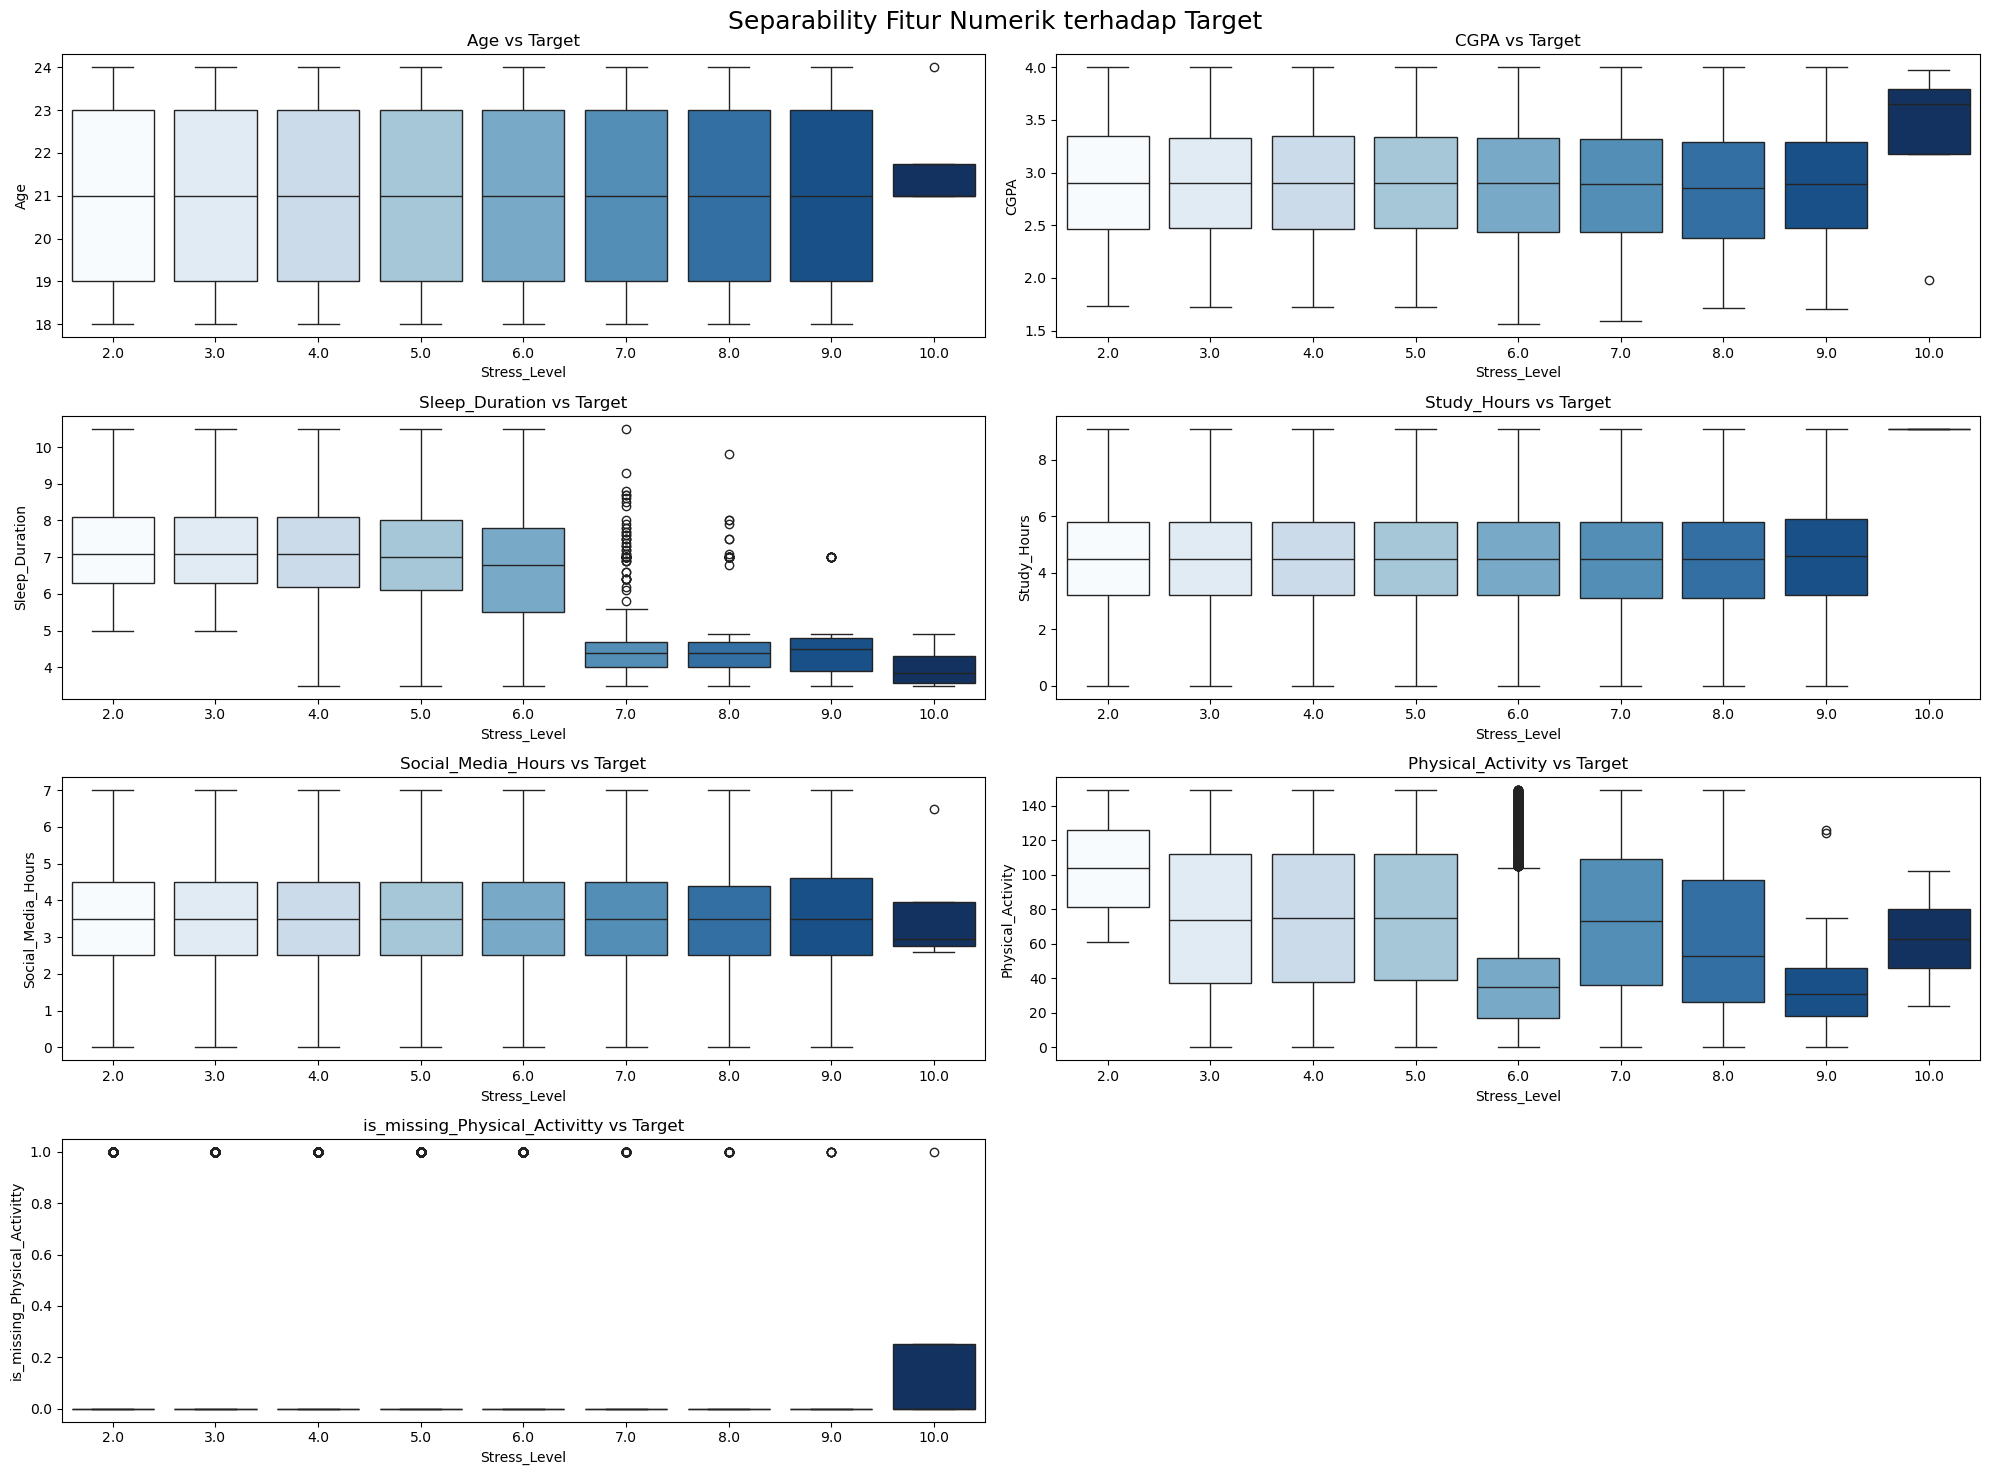

In [379]:
# Separability Fitur Numerik terhadap Target (Boxplot)
plt.figure(figsize=(20, 15))

for i, col in enumerate(num_cols):
    plt.subplot(int(len(num_cols)/2)+1, 2, i+1)
    sns.boxplot(x=y, y=X[col], hue=y, legend=False, palette='Blues')
    plt.title(f'{col} vs Target')
    
plt.suptitle('Separability Fitur Numerik terhadap Target', fontsize=18)
plt.tight_layout()
plt.show()

#### Technical Insight
- **Sleep_Duration** menunjukkan separability paling kuat, semakin tinggi `Stress_Level`, durasi tidur juga turun sekitar 4–5 jam dibanding level rendah (2–6) yang cenderung lebih tinggi sekitar 6–8 jam. Overlap antar kelas relatif kecil, menunjukkan fitur ini sangat informatif
- **CGPA** memiliki sinyal terutama pada `Stress_Level = 10` terlihat memiliki median CGPA lebih tinggi, sementara kelas 2–9 cukup overlap
- **Age** hampir tidak membedakan target
- **Study_Hours** dan **Social_Media_Hours** ada perbedaan sedikit per kelas tapi overlap masih besar
- **Physical_Activity** menunjukkan variasi besar dan banyak outlier, ada perbedaan antar kelas tetapi overlap besar

#### Domain Insight 
- Pola **Sleep_Duration menurun saat stres meningkat** berarti stres yang lebih tinggi sering disebabkan kurang tiduratau istirahat yang tidak cukup
- **Physical_Activity** mengindikasikan perilaku aktivitas fisik mahasiswa bermacam-macam
- **CGPA tinggi pada stres ekstrem** bisa sebagai indikasi pressure akademik pada beberapa kelompok

#### Keputusan (Action)
- Prioritas fitur untuk modelling: `Sleep_Duration` (kuat), `Physical_Activity` (sedang)

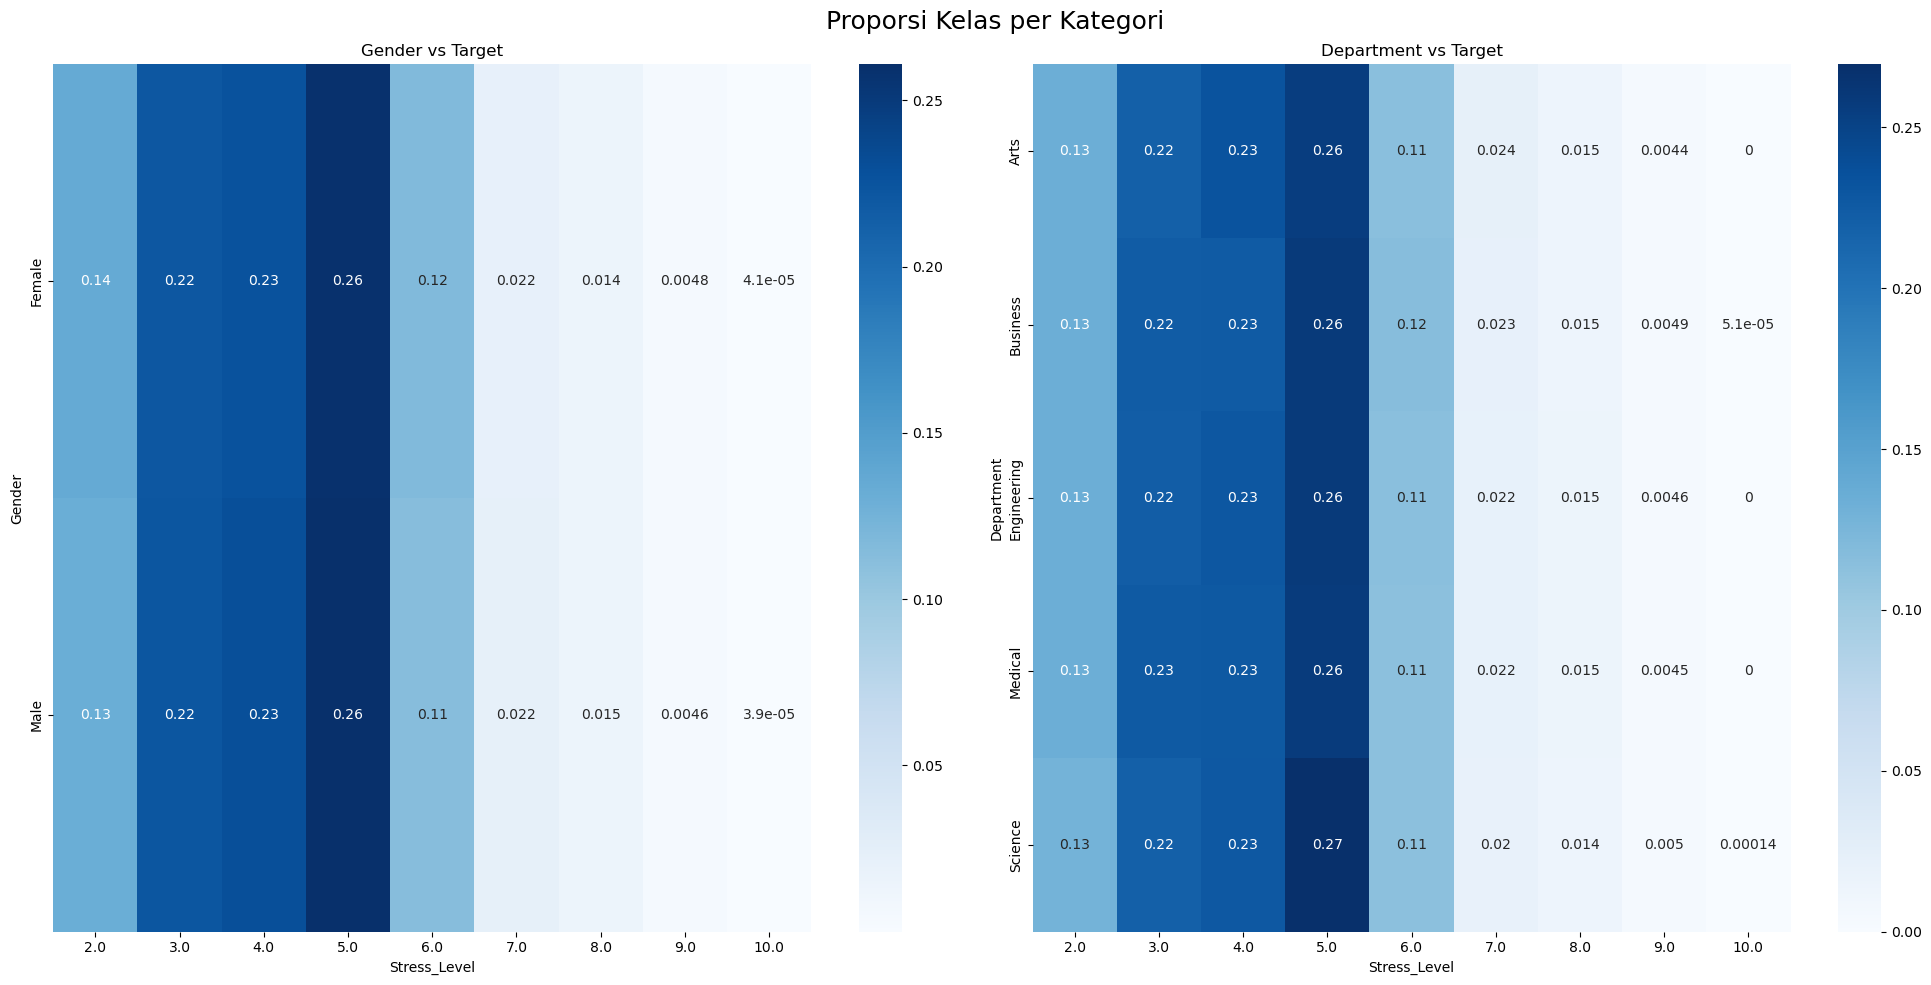

In [380]:
# Proporsi Kelas per Kategori
plt.figure(figsize=(20,10))

for idx in range(len(cat_cols)):
    col = cat_cols[idx]
    ax = plt.subplot(int(len(cat_cols)/2), 2, idx+1)
    sns.heatmap(pd.crosstab(X[col], y, normalize='index'), annot=True, cmap='Blues')
    plt.title(f'{col} vs Target')
    
plt.suptitle('Proporsi Kelas per Kategori', fontsize=18)
plt.tight_layout()
plt.show()

#### Technical Insight
- Untuk **Gender**, pola proporsi Stress_Level antara **Male vs Female hampir identik** di semua level, berarti  ini memiliki separability rendah terhadap target
- Untuk **Department**, tiap jurusan juga menunjukkan proporsi yang **mirip**, fitur ini cenderung lemah membedakan target

#### Domain Insight
- Stres tidak berbeda secara signifikan berdasarkan jenis kelamin
- Pola Department yang mirip mengindikasikan kalo **tingkat stres relatif konsisten antar jurusan**, faktor stres mungkin bisa lebih dipengaruhi perilaku daripada identitas jurusan.

#### Keputusan Preprocessing (Action)
- Tidak terlihat kategori yang condong ke kelas tertentu

## ⚙️ Data Classification

### ⚙️ Train-Test Split

In [381]:
def stratified_split(X, y, test_size=0.2, random_state=42):

    rng = np.random.default_rng(random_state)

    train_idx = []
    test_idx = []

    classes = y.unique()
    for cls in classes:
        idx = np.where(y == cls)[0]

        rng.shuffle(idx)

        n_test = int(np.round(len(idx) * test_size))
        
        test_idx.extend(idx[:n_test])
        train_idx.extend(idx[n_test:])

        rng.shuffle(train_idx)
        rng.shuffle(test_idx)

    X_train = X.iloc[train_idx]    
    X_test = X.iloc[test_idx]  
    
    y_train = y.iloc[train_idx]    
    y_test = y.iloc[test_idx]

    return X_train, X_test, y_train, y_test    

In [382]:
X_train, X_test, y_train, y_test = stratified_split(X, y)

print(f'X_train shape: {X_train.shape}')
print(f'X_test shape: {X_test.shape}')
print(f'y_train shape: {y_train.shape}')
print(f'y_test shape: {y_test.shape}')

X_train shape: (79999, 9)
X_test shape: (20001, 9)
y_train shape: (79999,)
y_test shape: (20001,)


### ⚙️ Feature Selection

📝 Feature selection akan dilakukan menggunakan metode **Mutual Information**

In [383]:
def mutual_information(X, y):
    joint = Counter(zip(X, y))
    px = Counter(X)
    py = Counter(y)
    m = X.shape[0]
    eps = 1e-8
    
    mi = 0.0
    for ((xi, yi), c_xy) in joint.items():
        p_xy = c_xy / m
        p_x = px[xi] / m
        p_y = py[yi] / m
        mi += p_xy * np.log(p_xy / (p_x * p_y) + eps)
    
    return mi

In [384]:
mi_scores = {}

for col in num_cols:
    x_binned = pd.qcut(X_train[col], q=5, duplicates='drop')
    mi_scores[col] = mutual_information(x_binned, y_train)

for col in cat_cols:
    mi_scores[col] = mutual_information(X_train[col], y_train)

mi_scores['target'] = mutual_information(y, y)

mi_table = pd.DataFrame({
    'columns': mi_scores.keys(),
    'mi scores': mi_scores.values()
}).sort_values('mi scores', ascending=False).reset_index(drop=True)

mi_table

,columns,mi scores
0,target,1.710293e+00
1,Physical_Activity,1.287129e-01
2,Sleep_Duration,6.832453e-02
3,CGPA,3.016198e-04
4,Study_Hours,2.698955e-04
5,Department,2.420442e-04
6,Age,1.798744e-04
7,Social_Media_Hours,1.792810e-04
8,Gender,5.581930e-05
9,is_missing_Physical_Activitty,1.000000e-08


Text(0, 0.5, 'Columns')

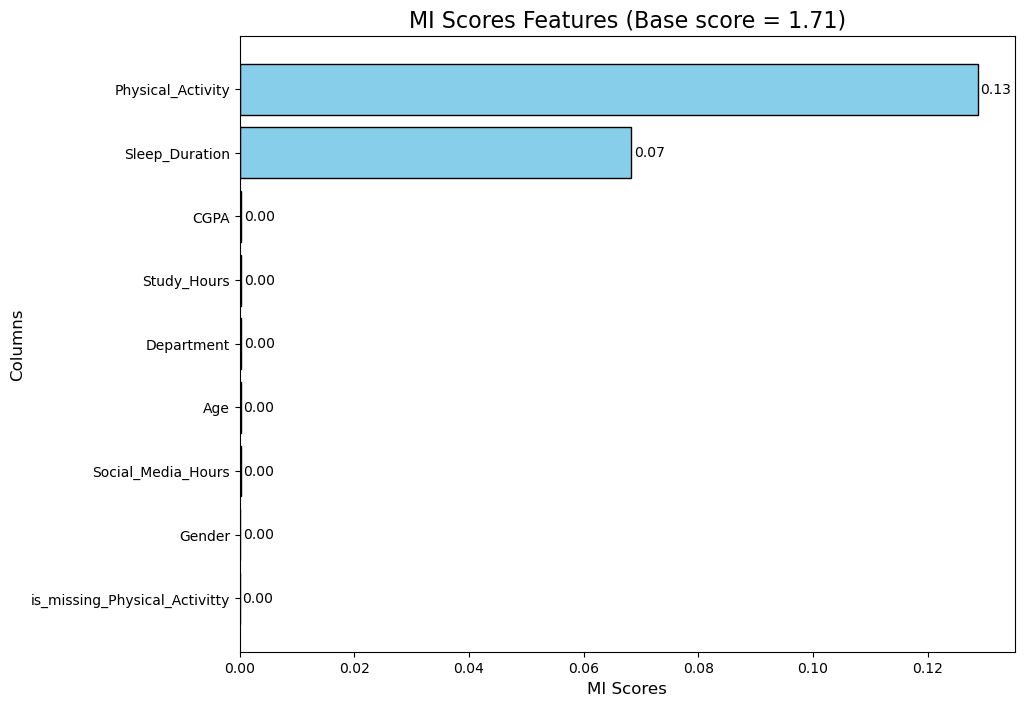

In [385]:
feature_mi = mi_table.loc[1:].sort_values('mi scores')
target_mi = mi_table.loc[0]

plt.figure(figsize=(10, 8))
bars = plt.barh(feature_mi['columns'], feature_mi['mi scores'], color='skyblue', edgecolor='black')
plt.bar_label(bars, fmt="%.2f", padding=2)
plt.title(f'MI Scores Features (Base score = {target_mi["mi scores"].round(2)})', fontsize=16)
plt.xlabel('MI Scores', fontsize=12)
plt.ylabel('Columns', fontsize=12)

✍️ Feature `Physical_Activity` dan `Sleep_Duration` memiliki informasi signifikan dibanding feature-feature lain

In [386]:
selected_features = ['Physical_Activity', 'Sleep_Duration', 'is_missing_Physical_Activitty']

X_train_selected, X_test_selected = X_train[selected_features].copy(), X_test[selected_features].copy()

X_train_selected.head()

,Physical_Activity,Sleep_Duration,is_missing_Physical_Activitty
31808,88.0,7.6,0
77362,58.0,7.0,0
98389,30.0,5.2,0
90682,107.0,6.5,0
3510,112.0,7.9,0


### ⚙️ Data Normalization

In [387]:
norm_cols = ['Physical_Activity', 'Sleep_Duration']

scaler = StandardScaler()
X_train_selected[norm_cols] = scaler.fit_transform(X_train_selected[norm_cols])
X_test_selected[norm_cols] = scaler.transform(X_test_selected[norm_cols])

X_train_selected.head()

,Physical_Activity,Sleep_Duration,is_missing_Physical_Activitty
31808,0.316580,0.414443,0
77362,-0.381335,0.004121,0
98389,-1.032723,-1.226844,0
90682,0.758593,-0.337813,0
3510,0.874912,0.619604,0


### ⚙️ Model Building

In [388]:
@dataclass
class LinearRegressionClassificationState:
    classes_: List[Any]
    W: np.ndarray
    l2_lambda: float

class LinearRegressionClassification:
    def __init__(self, l2_lambda: float = 0.0, random_state: int = 42):
        '''
        Glossary:
        m = jumlah rows
        n = jumlah columns
        '''
        self.l2_lambda = l2_lambda
        self.random_state = random_state

        self.state: LinearRegressionClassificationState | None = None
    
    @staticmethod
    def _add_intercept(X: np.ndarray):
        ones = np.ones((X.shape[0], 1), dtype=float)
        return np.hstack((ones, X), dtype=float)

    @staticmethod
    def _validate_input(X: np.ndarray, y: np.ndarray):
        if X.ndim != 2:
            raise ValueError("Feature X harus 2 dimensi.")
        
        if y.ndim != 1:
            raise ValueError("Target y harus 1 dimensi.")
        
        if X.shape[0] != y.shape[0]:
            raise ValueError("Jumlah row feature X dan target y harus sama.")

    def fit(self, X: np.ndarray | pd.DataFrame, y: np.ndarray | pd.Series):
        X, y = np.asarray(X), np.asarray(y)

        # add intercept to X: shape = (m, n+1)
        Xb = self._add_intercept(X)
        m, n = Xb.shape

        # classes preparation: shape = (K,)
        classes = np.unique(y).tolist()
        K = len(classes)

        # ridge matrix: shape = (n, n)
        if self.l2_lambda > 0.0:
            I = np.eye(n, dtype=float)
            I[0, 0] = 0.0
        else:
            I = 0.0

        # parameter init: shape = (K, n)
        rng = np.random.RandomState(self.random_state)
        W = rng.normal(loc=0.0, scale=0.01, size=(K, n))

        # RHS Normal Equation
        A = (Xb.T @ Xb) + (self.l2_lambda * I)

        # training loop
        for k, c in enumerate(classes):
            # class ke-k: shape = (m,)
            yk = (y == c).astype(int)

            # LHS Normal Equation
            b = Xb.T @ yk

            # parameter ke-k: shape = (K,)
            try:
                wk = np.linalg.solve(A, b)
            
            except np.linalg.LinAlgError:
                wk = np.linalg.lstsq(A, b, rcond=False)[0]

            W[k, :] = wk

        self.state = LinearRegressionClassificationState(classes_=classes, W=W,
                                                         l2_lambda=self.l2_lambda)

    def predict(self, X: np.ndarray | pd.DataFrame):
        if self.state is None:
            raise RuntimeError('Model belum di training, jalankan fit().')
        
        st = self.state

        X = np.asarray(X)
        Xb = self._add_intercept(X)

        # predicted scores: shape = (m, K)
        scores = Xb @ st.W.T

        if len(st.classes_) == 2:
            pos_scores = scores[:, 1] if scores.shape[1] > 1 else scores[:, 0]
            self.predicted_scores = pos_scores
            return np.where(pos_scores >= st.threshold, st.classes_[1], st.classes_[0])
        
        idx = np.argmax(scores, axis=1).astype(int)
        self.predicted_scores = scores
        return np.array([st.classes_[i] for i in idx], dtype=object)

### ⚙️ Hyperparameter Tuning

#### ⚙️ Cross Validation

In [389]:
def stratified_cv_indices(y, k=5, shuffle=True, random_state=42):

    y = np.asarray(y).ravel()
    n = y.shape[0]
    rng = np.random.default_rng(random_state)

    classes = np.unique(y)
    folds = [[] for _ in range(k)]

    for cls in classes:
        idx_c = np.where(y == cls)[0]

        if shuffle:
            rng.shuffle(idx_c)

        for i, idx_val in enumerate(idx_c):
            folds[i % k].append(idx_val)

    all_idx = np.arange(n)
    for i in range(k):
        test_idx = np.array(folds[i], dtype=int)
        test_idx.sort()

        train_mask = np.ones(n, dtype=bool)
        train_mask[test_idx] = False
        train_idx = all_idx[train_mask]

        yield train_idx, test_idx

def scores_cv(model_ctor, X, y, k=5, shuffle=True, random_state=42):
    
    X = np.asarray(X)
    y = np.asarray(y).ravel()

    scores = []

    for tr, te in stratified_cv_indices(y, k=k, shuffle=shuffle, random_state=random_state):
        model = model_ctor()

        model.fit(X[tr], y[tr])
        pred = model.predict(X[te])
        scores.append(np.mean(pred == y[te]))

    scores = np.asarray(scores, dtype=float)

    return scores, float(np.mean(scores))

#### ⚙️ Brute Force Searching

In [390]:
def tuning(X, y,
           model_class, scores_cv_fn=scores_cv,
           k=5, shuffle=True, random_state=42,
           l2_grid=None):
    
    if l2_grid is None:
        l2_grid = [0, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1]


    results = []
    best_row = None
    
    for l2 in l2_grid:

        def model_ctor(l2=l2):
            return model_class(l2_lambda=l2)
        
        folds_scores, mean_score = scores_cv_fn(
            X=X, y=y,
            model_ctor=model_ctor,
            k=k, shuffle=shuffle, random_state=random_state
        )
        folds_std = folds_scores.std(ddof=0)

        row = {
            'l2_lambda': l2,
            'folds_scores': folds_scores,
            'mean_score': mean_score,
            'folds_std': folds_std
        }
        results.append(row)

        if best_row is None:
            best_row = row
        
        else:
            if (row['mean_score'] > best_row['mean_score']) or (
                row['mean_score'] == best_row['mean_score'] and row['folds_std'] < best_row['folds_std']
            ):
                best_row = row

    summary = pd.DataFrame(results, columns=['l2_lambda', 'folds_scores', 'mean_score', 'folds_std'])
    best_params = {'l2_lambda': best_row['l2_lambda']}

    return best_params, summary

In [391]:
best_params, summary = tuning(X_train_selected, y_train, model_class=LinearRegressionClassification)
summary

,l2_lambda,folds_scores,mean_score,folds_std
0,0.000000,"[0.2583427071616048, 0.2572803399575053, 0.254...",0.257441,0.001697
1,0.000001,"[0.2583427071616048, 0.2572803399575053, 0.254...",0.257441,0.001697
2,0.000010,"[0.2583427071616048, 0.2572803399575053, 0.254...",0.257441,0.001697
3,0.000100,"[0.2583427071616048, 0.2572803399575053, 0.254...",0.257441,0.001697
4,0.001000,"[0.2583427071616048, 0.2572803399575053, 0.254...",0.257441,0.001697
5,0.010000,"[0.2583427071616048, 0.2572803399575053, 0.254...",0.257441,0.001697
6,0.100000,"[0.2583427071616048, 0.2572803399575053, 0.254...",0.257441,0.001697
7,1.000000,"[0.2583427071616048, 0.2572803399575053, 0.254...",0.257441,0.001697


✍️ Performa model menunjukkan **akurasi rendah (~25%)**, kita coba gunakan semua feature

### ⚙️ Experiment: Memakai Semua Feature

#### ⚙️ Encoding Feature Kategorik 

In [392]:
print(f'Proporsi Gender pada X_train:\n{X_train["Gender"].value_counts()}\n')
print(f'Proporsi Gender pada X_test:\n{X_test["Gender"].value_counts()}\n\n')

print(f'Proporsi Department pada X_train:\n{X_train["Department"].value_counts()}\n')
print(f'Proporsi Department pada X_test:\n{X_test["Department"].value_counts()}\n\n')

Proporsi Gender pada X_train:
Gender
Male      40837
Female    39162
Name: count, dtype: int64

Proporsi Gender pada X_test:
Gender
Male      10245
Female     9756
Name: count, dtype: int64


Proporsi Department pada X_train:
Department
Science        17299
Engineering    15749
Medical        15675
Arts           15645
Business       15631
Name: count, dtype: int64

Proporsi Department pada X_test:
Department
Science        4350
Arts           3934
Engineering    3917
Medical        3903
Business       3897
Name: count, dtype: int64




✍️ Training dan testing dataset keduanya memiliki **proporsi kategori yang seimbang**

In [393]:
# encode dan feature engineering 'Gender'
X_train_encoded, X_test_encoded = X_train.copy(), X_test.copy()

X_train_encoded['is_male'] = X_train_encoded['Gender'].map(lambda x: 1 if x == 'Male' else 0)
X_test_encoded['is_male'] = X_test_encoded['Gender'].map(lambda x: 1 if x == 'Male' else 0)

X_train_encoded = X_train_encoded.drop(columns=['Gender'])
X_test_encoded = X_test_encoded.drop(columns=['Gender'])

X_train_encoded.head()

,Age,Department,CGPA,Sleep_Duration,Study_Hours,Social_Media_Hours,Physical_Activity,is_missing_Physical_Activitty,is_male
31808,24.0,Engineering,2.57,7.6,2.8,2.3,88.0,0,0
77362,19.0,Medical,3.25,7.0,4.5,4.3,58.0,0,0
98389,21.0,Science,3.27,5.2,6.4,5.3,30.0,0,1
90682,24.0,Engineering,3.90,6.5,7.1,5.0,107.0,0,1
3510,18.0,Business,2.79,7.9,6.0,3.1,112.0,0,1


In [394]:
X_train_encoded = pd.get_dummies(X_train_encoded, columns=['Department'], prefix='Dep').astype(float)
X_test_encoded = pd.get_dummies(X_test_encoded, columns=['Department'], prefix='Dep').astype(float)

X_train_encoded.head()

,Age,CGPA,Sleep_Duration,Study_Hours,Social_Media_Hours,Physical_Activity,is_missing_Physical_Activitty,is_male,Dep_Arts,Dep_Business,Dep_Engineering,Dep_Medical,Dep_Science
31808,24.0,2.57,7.6,2.8,2.3,88.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
77362,19.0,3.25,7.0,4.5,4.3,58.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
98389,21.0,3.27,5.2,6.4,5.3,30.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
90682,24.0,3.90,6.5,7.1,5.0,107.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
3510,18.0,2.79,7.9,6.0,3.1,112.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


#### ⚙️ Re-Normalize kolom numerik

In [395]:
norm_cols = num_cols[:-1]

X_train_scaled, X_test_scaled = X_train_encoded.copy(), X_test_encoded.copy()

scaler = StandardScaler()

X_train_scaled[norm_cols] = scaler.fit_transform(X_train_scaled[norm_cols])
X_test_scaled[norm_cols] = scaler.transform(X_test_scaled[norm_cols])

X_train_scaled.head()

,Age,CGPA,Sleep_Duration,Study_Hours,Social_Media_Hours,Physical_Activity,is_missing_Physical_Activitty,is_male,Dep_Arts,Dep_Business,Dep_Engineering,Dep_Medical,Dep_Science
31808,1.513775,-0.619893,0.414443,-0.879000,-0.821408,0.316580,0.0,0.0,0.0,0.0,1.0,0.0,0.0
77362,-1.014979,0.671161,0.004121,-0.000561,0.549356,-0.381335,0.0,0.0,0.0,0.0,0.0,1.0,0.0
98389,-0.003477,0.709134,-1.226844,0.981223,1.234737,-1.032723,0.0,1.0,0.0,0.0,0.0,0.0,1.0
90682,1.513775,1.905257,-0.337813,1.342933,1.029123,0.758593,0.0,1.0,0.0,0.0,1.0,0.0,0.0
3510,-1.520729,-0.202199,0.619604,0.774531,-0.273102,0.874912,0.0,1.0,0.0,1.0,0.0,0.0,0.0


#### ⚙️ Re-Tuning Model

In [396]:
best_params, summary = tuning(X_train_scaled, y_train, model_class=LinearRegressionClassification)
summary

,l2_lambda,folds_scores,mean_score,folds_std
0,0.000000,"[0.2574053243344582, 0.2579677540307462, 0.258...",0.258166,0.000445
1,0.000001,"[0.2574053243344582, 0.2579677540307462, 0.258...",0.258166,0.000445
2,0.000010,"[0.2574053243344582, 0.2579677540307462, 0.258...",0.258166,0.000445
3,0.000100,"[0.2574053243344582, 0.2579677540307462, 0.258...",0.258166,0.000445
4,0.001000,"[0.2574053243344582, 0.2579677540307462, 0.258...",0.258166,0.000445
5,0.010000,"[0.2574053243344582, 0.2579677540307462, 0.258...",0.258166,0.000445
6,0.100000,"[0.2574053243344582, 0.2579677540307462, 0.258...",0.258166,0.000445
7,1.000000,"[0.2574053243344582, 0.2579677540307462, 0.258...",0.258166,0.000445


✍️ Menggunakan semua kolom dan hanya `Physical_Activity` + `Sleep_Duration` **tidak memberikan perubahan performa signifikan** </br>
✍️ Maka dari itu untuk efisiensi, hanya kolom `Physical_Activity` + `Sleep_Duration` yang akan digunakan</br>

### ⚙️ Final Model

⭐ Feature yang digunakan: `Physical_Activity` (termasuk *missing indicator*) dan `Sleep_Duration` </br>
⭐ Parameter model: **l2_lambda = 0** (default) </br>

In [397]:
final_model = LinearRegressionClassification()
final_model.fit(X_train_selected, y_train)
print('Model final telah dilatih!')

Model final telah dilatih!


### ⚙️ Decision Boundary

#### ⚙️ Dimensional Reduction

In [398]:
class PCA:
    def __init__(self, n_components: int = 2):
        self.n_components = n_components
        self.mean_ = None
        self.components = None

        self.explained_variance_ = None
        self.explained_variance_ratio_ = None
        self.singular_values_ = None

    def fit(self, X: np.ndarray | pd.DataFrame):
        X = np.asarray(X)
        m, n = X.shape

        self.mean_ = X.mean(axis=0)
        Xc = X - self.mean_

        U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
        
        # komponen utama 
        self.components = Vt[:self.n_components].T

        self.singular_values_ = S

        # variance per PC
        explained_variance_all = (S ** 2) / (m - 1)

        total_var = explained_variance_all.sum()
        explained_variance_ratio_all = explained_variance_all / total_var

        self.explained_variance_ = explained_variance_all
        self.explained_variance_ratio_ = explained_variance_ratio_all

        return self
    
    def transform(self, X: np.ndarray | pd.DataFrame):
        X = np.asarray(X, dtype=float)
        Xc = X - self.mean_
        return Xc @ self.components
    
    def fit_transform(self, X: np.ndarray | pd.DataFrame):
        return self.fit(X).transform(X)


In [399]:
pca = PCA()

X_train_pca = pca.fit_transform(X_train_selected)
X_test_pca = pca.transform(X_test_selected)

X_train_pca

array([[-0.51691254,  0.06919783],
       [ 0.26672987,  0.27255491],
       [ 1.59775292, -0.1372721 ],
       ...,
       [ 1.11915297,  0.83483265],
       [ 0.26076905, -0.31368665],
       [-0.24079633,  1.60258742]])

In [400]:
evr = pca.explained_variance_ratio_
pca_report = pd.DataFrame({
    'PC': np.arange(1, len(evr)+1),
    'EVR': evr
})


print(f'EVR PC1 dan PC2: {pca.explained_variance_ratio_[:2].sum()}')
display(pca_report)

EVR PC1 dan PC2: 0.9904480718643802


,PC,EVR
0,1,0.496434
1,2,0.494014
2,3,0.009552


✍️ PC1 dan PC2 sudah mencakup **~99% variansi data**

#### ⚙️ 2D Plot of Decision Boundary

In [401]:
def plot_regions_multiclass(model, Z, y, grid=250, scatter_alpha=0.7, contour_alpha=0.25, title="Decision Regions in PCA Space"):
    st = model.state
    W = st.W  # (K, 3)

    z1_min, z1_max = Z[:, 0].min(), Z[:, 0].max()
    z2_min, z2_max = Z[:, 1].min(), Z[:, 1].max()

    xx, yy = np.meshgrid(
        np.linspace(z1_min, z1_max, grid),
        np.linspace(z2_min, z2_max, grid)
    )

    # buat semua titik grid jadi (N,2)
    G = np.c_[xx.ravel(), yy.ravel()]                       # (grid^2, 2)
    Gb = np.hstack([np.ones((G.shape[0], 1)), G])          # add bias -> (grid^2, 3)

    # skor semua kelas: (grid^2, K)
    scores = Gb @ W.T

    classes = np.unique(y)          # misal [2,3,4,...,10]
    pred_idx = np.argmax(scores, axis=1)
    pred_label = classes[pred_idx].reshape(xx.shape)


    plt.figure()
    plt.contourf(xx, yy, pred_label, alpha=contour_alpha)

    unique_preds = np.unique(pred_label)
    print("Kelas yang muncul di region:", unique_preds)

    # overlay titik data
    for c in classes:
        m = (y == c)
        plt.scatter(Z[m, 0], Z[m, 1], s=10, alpha=scatter_alpha, label=str(c))

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.legend() if scatter_alpha > 0 else None
    plt.tight_layout()
    plt.show()


In [402]:
# preparation
viz_model = LinearRegressionClassification()
viz_model.fit(X_train_pca, y_train)

Z = np.vstack((X_train_pca, X_test_pca), dtype=float)
y = np.concatenate([y_train, y_test])


Kelas yang muncul di region: [2. 3. 5. 6.]


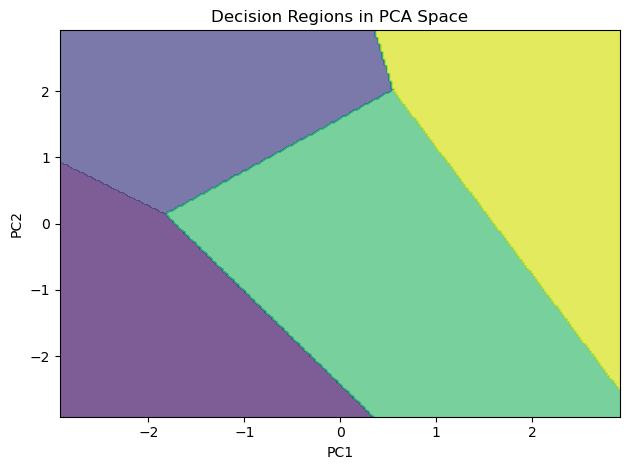

Kelas yang muncul di region: [2. 3. 5. 6.]


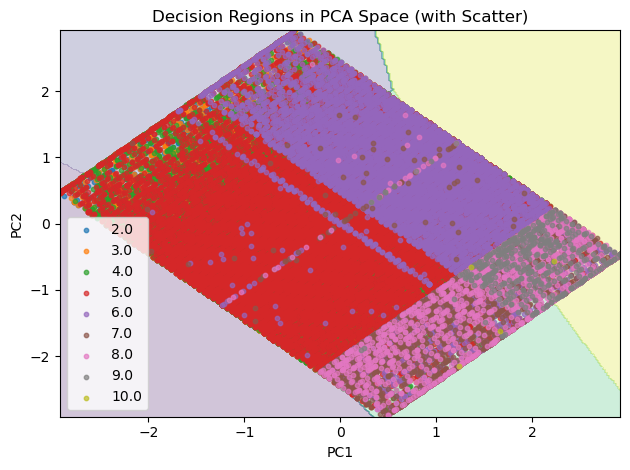

In [403]:
title = "Decision Regions in PCA Space"
plot_regions_multiclass(viz_model, Z, y, scatter_alpha=0, contour_alpha=0.7)
plot_regions_multiclass(viz_model, Z, y, title=title + " (with Scatter)")

✍️ **Insight Utama**

* Region contour = **kelas yang diprediksi model** di tiap titik (PC1, PC2).
* Boundary berbentuk **garis lurus/poligon** → modelmu **linear**, jadi kapasitasnya terbatas (Tier 1).
* Titik antar kelas **banyak overlap** di PC1–PC2 → kelas `stress_level` **sulit dipisah** dengan model linear.
* Karena `EVR(PC1+PC2) ≈ 0.99` (awal 3 fitur), plot ini **valid merepresentasikan data** → overlap ini kemungkinan **masalah nyata**, bukan efek PCA.

## 📝 Model Evaluation

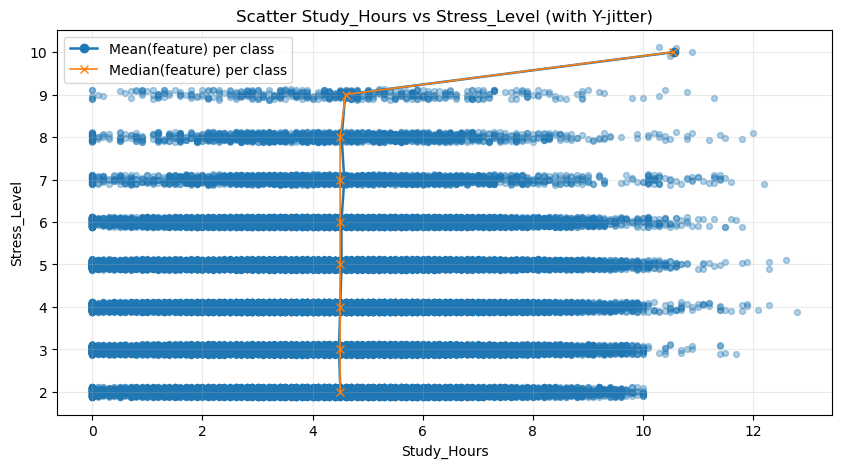

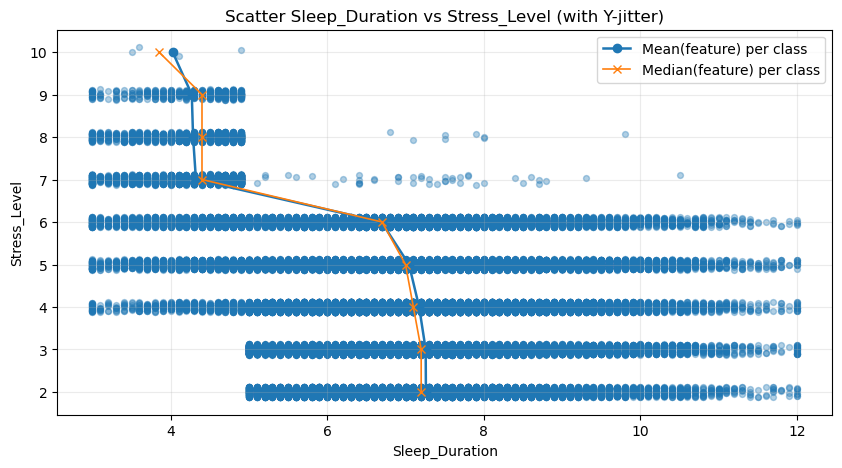

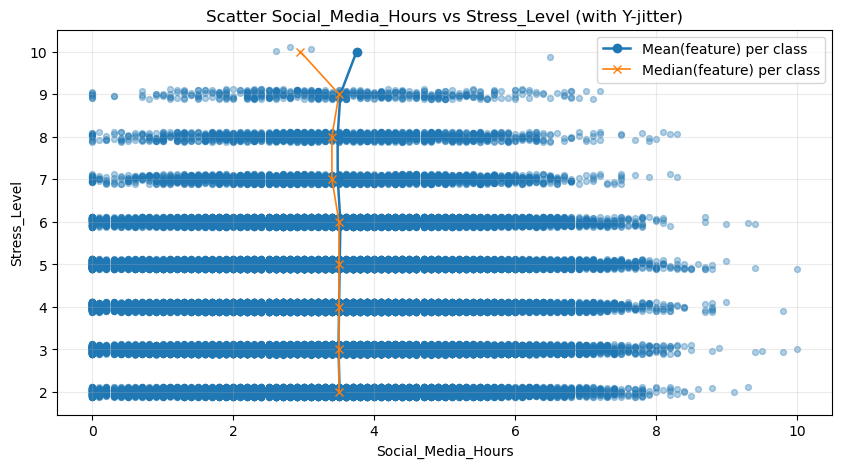

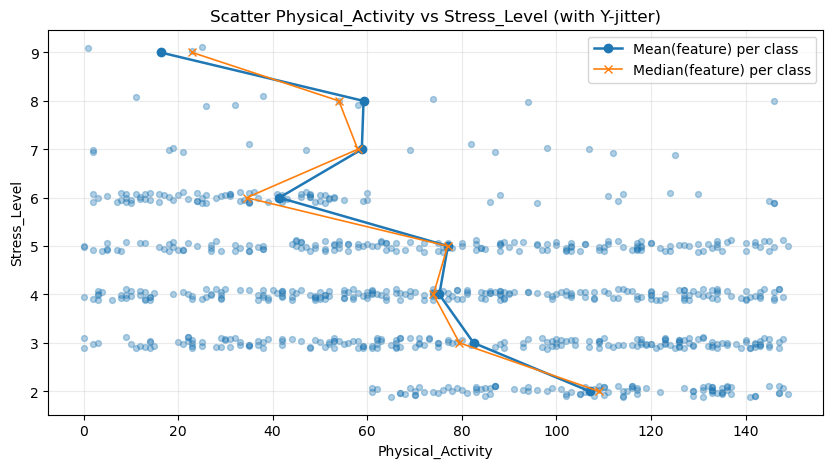

In [404]:
import numpy as np
import matplotlib.pyplot as plt

def scatter_feature_vs_ordinal_target_with_jitter(
    df,
    feature_col: str,
    target_col: str = "Stress_Level",
    jitter: float = 0.12,
    sample_n: int | None = None,
    random_state: int = 42,
    show_mean_median: bool = True,
):
    """
    Scatter plot: X = feature (numeric), Y = ordinal target (discrete) + jitter.
    Optional: overlay mean/median feature value per target class.

    Works well for ordinal classification labels like 1..10.
    Uses only numpy + matplotlib.
    """

    # ambil data valid
    sub = df[[feature_col, target_col]].dropna().copy()

    # optional sampling (biar nggak terlalu padat)
    if sample_n is not None and sample_n < len(sub):
        sub = sub.sample(sample_n, random_state=random_state)

    x = sub[feature_col].to_numpy(dtype=float)
    y = sub[target_col].to_numpy(dtype=float)

    # jitter di Y supaya nggak numpuk
    rng = np.random.default_rng(random_state)
    y_jitter = y + rng.uniform(-jitter, jitter, size=len(y))

    # scatter
    plt.figure(figsize=(10, 5))
    plt.scatter(x, y_jitter, alpha=0.35, s=18)

    # label dan grid
    plt.title(f"Scatter {feature_col} vs {target_col} (with Y-jitter)")
    plt.xlabel(feature_col)
    plt.ylabel(target_col)
    plt.grid(True, alpha=0.25)

    # batasi yticks ke kelas-kelas yang ada
    classes = np.sort(np.unique(y))
    plt.yticks(classes)

    # overlay mean/median feature per kelas target
    if show_mean_median:
        mean_x = []
        median_x = []
        y_levels = []

        for c in classes:
            xc = x[y == c]
            if len(xc) == 0:
                continue
            mean_x.append(np.mean(xc))
            median_x.append(np.median(xc))
            y_levels.append(c)

        # plot mean & median (X per kelas, Y = level kelas)
        plt.plot(mean_x, y_levels, marker="o", linewidth=1.8, label="Mean(feature) per class")
        plt.plot(median_x, y_levels, marker="x", linewidth=1.2, label="Median(feature) per class")
        plt.legend()

    plt.show()


# ======= CONTOH PAKAI =======
# df = pd.read_csv("./Student lifestyle data.csv")
scatter_feature_vs_ordinal_target_with_jitter(df, feature_col="Study_Hours", target_col="Stress_Level")
scatter_feature_vs_ordinal_target_with_jitter(df, feature_col="Sleep_Duration", target_col="Stress_Level")
scatter_feature_vs_ordinal_target_with_jitter(df, feature_col="Social_Media_Hours", target_col="Stress_Level")
scatter_feature_vs_ordinal_target_with_jitter(df, feature_col="Physical_Activity", target_col="Stress_Level", sample_n=800)